In [1]:
%matplotlib inline
import numpy as np
import spectral
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

# Força spectral a usar matplotlib (renderiza inline no Jupyter)
spectral.settings.imshow_backend = 'matplotlib'
matplotlib.rcParams['figure.dpi'] = 100

In [2]:
ROOT_DIR = Path("..").resolve()
PATH_CALIBRADOS = ROOT_DIR / "data" / "silver level" / "hsi_calibrado"

print(PATH_CALIBRADOS)
list(PATH_CALIBRADOS.glob("*.npy"))[:5]

D:\IC PUC\HSI-Pipeline-Automation\data\silver level\hsi_calibrado


[WindowsPath('D:/IC PUC/HSI-Pipeline-Automation/data/silver level/hsi_calibrado/3491B_240506-155911.npy'),
 WindowsPath('D:/IC PUC/HSI-Pipeline-Automation/data/silver level/hsi_calibrado/351_1_240506-160920.npy'),
 WindowsPath('D:/IC PUC/HSI-Pipeline-Automation/data/silver level/hsi_calibrado/420_240506-160205.npy'),
 WindowsPath('D:/IC PUC/HSI-Pipeline-Automation/data/silver level/hsi_calibrado/426_1_240506-160058.npy'),
 WindowsPath('D:/IC PUC/HSI-Pipeline-Automation/data/silver level/hsi_calibrado/491_240506-160846.npy')]

In [3]:
sample_path = list(PATH_CALIBRADOS.glob("*.npy"))[0]
cube = np.load(sample_path)

cube.shape

(291, 320, 256)

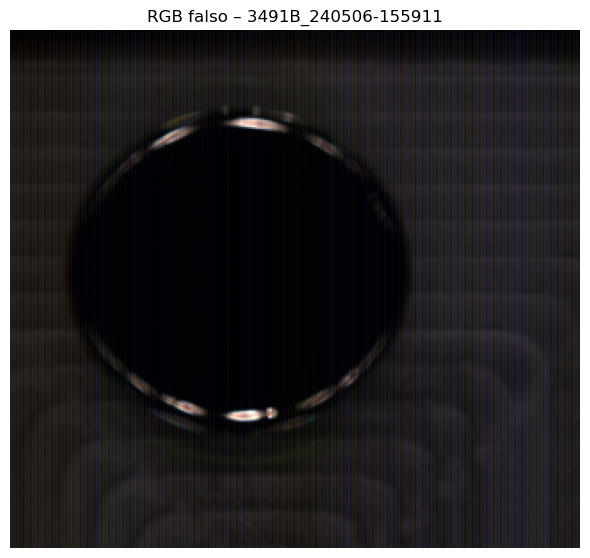

In [4]:
# Gera imagem RGB falso-cor via spectral e exibe com matplotlib
rgb = spectral.get_rgb(cube, bands=(135, 85, 35))
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)  # normaliza 0-1

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(rgb)
ax.set_title(f"RGB falso – {sample_path.stem}")
ax.axis('off')
plt.tight_layout()
plt.savefig("inspecao_rgb.png", dpi=100, bbox_inches='tight')
plt.show()

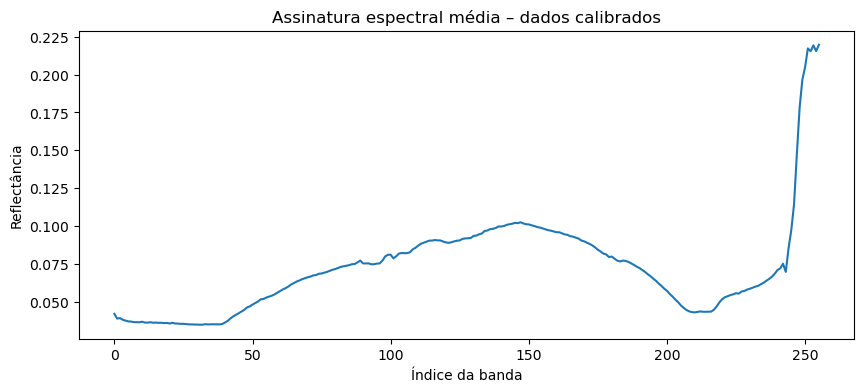

In [5]:
mean_spectrum = cube.mean(axis=(0, 1))

plt.figure(figsize=(10, 4))
plt.plot(mean_spectrum)
plt.title("Assinatura espectral média – dados calibrados")
plt.xlabel("Índice da banda")
plt.ylabel("Reflectância")
plt.show()

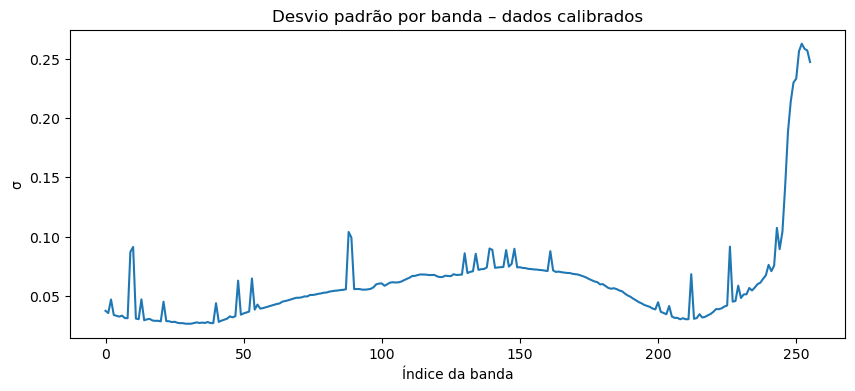

In [6]:
std_spectrum = cube.std(axis=(0, 1))

plt.figure(figsize=(10, 4))
plt.plot(std_spectrum)
plt.title("Desvio padrão por banda – dados calibrados")
plt.xlabel("Índice da banda")
plt.ylabel("σ")
plt.show()